# **Details:**

**Name:** Vinit Jadhav

**PRN:** 202401040163

**Division:** A

**Roll No.:** 38


# **Title**

Practical Assignment 04 – Classification Models

# **Aim**

To develop and evaluate classification models using Support Vector Machine (SVM), Decision Tree, K-Nearest Neighbors (KNN), and Naïve Bayes algorithms. The performance of each model is evaluated using accuracy, precision, recall, F1-score, and log loss, followed by a comparative analysis of their suitability for different classification tasks.

# **Experiment Objectives**

- To understand the basic concepts of classification in Machine Learning.
- To load and explore a real-world classification dataset.
- To preprocess the data and divide it into training and testing sets.
- To implement SVM, Decision Tree, KNN, and Naïve Bayes classifiers.
- To evaluate each classifier using accuracy, precision, recall, F1-score, and log loss.
- To compare the performance of the four classification algorithms.
- To understand the strengths, limitations, and suitable applications of each algorithm.

# **Experiment Outcome**

- Loaded and explored a real-world binary classification dataset.
- Prepared the dataset using stratified training and testing sets.
- Trained four different classification algorithms.
- Calculated accuracy, precision, recall, F1-score, and log loss.
- Compared model performance using a metric table and visualizations.
- Examined confusion matrices and classification reports.
- Identified situations in which each classification algorithm is useful.
- Discussed limitations, ethical considerations, and possible improvements.

# **Theory**

### 1. Classification

Classification is a supervised Machine Learning technique used to predict a category or class label. Unlike regression, which predicts a continuous numerical value, classification predicts discrete classes.

Examples include spam detection, disease classification, fraud detection, and customer churn prediction.

### 2. Support Vector Machine (SVM)

SVM finds a decision boundary, called a hyperplane, that separates classes. It attempts to maximize the margin between the classes. Kernels can help SVM learn non-linear decision boundaries.

**Advantages:** Effective in high-dimensional spaces and can model non-linear boundaries using kernels.

**Limitations:** Choosing the kernel and parameters can be difficult; training can be expensive on large datasets.

### 3. Decision Tree

A Decision Tree makes predictions by repeatedly splitting data using feature-based rules. Each internal node represents a decision, each branch represents an outcome, and each leaf represents a predicted class.

**Advantages:** Easy to understand and can model non-linear relationships.

**Limitations:** A deep tree can overfit the training data and may be sensitive to small changes in data.

### 4. K-Nearest Neighbors (KNN)

KNN predicts the class of a new observation by examining the classes of its nearest training observations. The most common class among the selected neighbors is used as the prediction.

**Advantages:** Simple, intuitive, and can model complex decision boundaries.

**Limitations:** Prediction can be slow on large datasets and performance depends on feature scaling and the choice of K.

### 5. Naïve Bayes

Naïve Bayes is a probabilistic classifier based on Bayes' theorem. It assumes that features are conditionally independent given the class.

**Advantages:** Fast, simple, and useful for high-dimensional data.

**Limitations:** The independence assumption may not hold in real datasets.

### 6. Classification Evaluation Metrics

- **Accuracy:** Proportion of all predictions that are correct.
- **Precision:** Proportion of predicted positive cases that are actually positive.
- **Recall:** Proportion of actual positive cases correctly identified.
- **F1-score:** Harmonic mean of precision and recall.
- **Log Loss:** Measures the quality of predicted class probabilities. Lower values indicate better-calibrated and more accurate probability estimates.

Accuracy alone can be misleading when classes are imbalanced. Precision and recall are important when false positives and false negatives have different consequences.

### 7. Dataset Used

The experiment uses the Wisconsin Diagnostic Breast Cancer dataset available through scikit-learn. It contains numerical measurements computed from digitized images of breast mass samples. The target has two classes: malignant and benign.

This dataset is used only for educational classification practice. The models are not medical diagnostic systems and must not be used to make healthcare decisions.

# **Problem Statement**

Develop classification models to classify observations in the Wisconsin Diagnostic Breast Cancer dataset as malignant or benign.

Implement the following algorithms:

1. Support Vector Machine (SVM)
2. Decision Tree Classifier
3. K-Nearest Neighbors (KNN)
4. Gaussian Naïve Bayes

Evaluate their performance using accuracy, precision, recall, F1-score, and log loss. Compare the results and discuss the suitability of each algorithm for different classification tasks.

# **1. Import Required Libraries**

Import libraries for data handling, visualization, preprocessing, classification algorithms, and performance evaluation.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")

Libraries imported successfully.


# **2. Load and Understand the Dataset**

Load the Wisconsin Diagnostic Breast Cancer dataset. Display its dimensions, feature names, class names, and first few records.

In [ ]:
dataset = load_breast_cancer(as_frame=True)

X = dataset.data
y = dataset.target

df = X.copy()
df["target"] = y

print("Dataset shape:", df.shape)
print("\nFeature count:", X.shape[1])
print("Class names:", list(dataset.target_names))
print("\nFirst five records:")
display(df.head())

print("\nDataset information:")
display(df.describe().round(2))

Dataset shape: (569, 31)

Feature count: 30
Class names: [np.str_('malignant'), np.str_('benign')]

First five records:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Dataset information:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00
mean,14.13,19.29,91.97,654.89,0.10,0.10,0.09,0.05,0.18,0.06,0.41,1.22,2.87,40.34,0.01,0.03,0.03,0.01,0.02,0.00,16.27,25.68,107.26,880.58,0.13,0.25,0.27,0.11,0.29,0.08,0.63
std,3.52,4.30,24.30,351.91,0.01,0.05,0.08,0.04,0.03,0.01,0.28,0.55,2.02,45.49,0.00,0.02,0.03,0.01,0.01,0.00,4.83,6.15,33.60,569.36,0.02,0.16,0.21,0.07,0.06,0.02,0.48
min,6.98,9.71,43.79,143.50,0.05,0.02,0.00,0.00,0.11,0.05,0.11,0.36,0.76,6.80,0.00,0.00,0.00,0.00,0.01,0.00,7.93,12.02,50.41,185.20,0.07,0.03,0.00,0.00,0.16,0.06,0.00
25%,11.70,16.17,75.17,420.30,0.09,0.06,0.03,0.02,0.16,0.06,0.23,0.83,1.61,17.85,0.01,0.01,0.02,0.01,0.02,0.00,13.01,21.08,84.11,515.30,0.12,0.15,0.11,0.06,0.25,0.07,0.00
50%,13.37,18.84,86.24,551.10,0.10,0.09,0.06,0.03,0.18,0.06,0.32,1.11,2.29,24.53,0.01,0.02,0.03,0.01,0.02,0.00,14.97,25.41,97.66,686.50,0.13,0.21,0.23,0.10,0.28,0.08,1.00
75%,15.78,21.80,104.10,782.70,0.11,0.13,0.13,0.07,0.20,0.07,0.48,1.47,3.36,45.19,0.01,0.03,0.04,0.01,0.02,0.00,18.79,29.72,125.40,1084.00,0.15,0.34,0.38,0.16,0.32,0.09,1.00
max,28.11,39.28,188.50,2501.00,0.16,0.35,0.43,0.20,0.30,0.10,2.87,4.88,21.98,542.20,0.03,0.14,0.40,0.05,0.08,0.03,36.04,49.54,251.20,4254.00,0.22,1.06,1.25,0.29,0.66,0.21,1.00


# **3. Exploratory Data Analysis**

Check for missing values and inspect the number of samples in each class. Visualize the class distribution to understand whether the dataset is balanced.

Missing values:
0

Class distribution:
malignant: 212
benign: 357


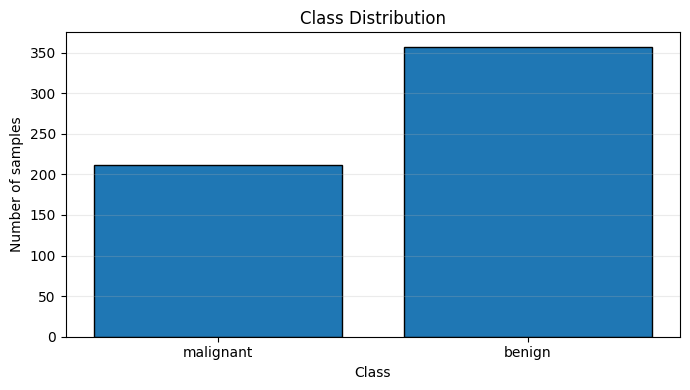

In [ ]:
print("Missing values:")
print(df.isnull().sum().sum())

class_counts = y.value_counts().sort_index()
class_labels = [dataset.target_names[i] for i in class_counts.index]

print("\nClass distribution:")
for label, count in zip(class_labels, class_counts.values):
    print(f"{label}: {count}")

plt.figure(figsize=(7, 4))
plt.bar(class_labels, class_counts.values, edgecolor="black")
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of samples")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# **4. Data Preprocessing**

Split the dataset into training and testing sets. Stratification preserves approximately the same class proportions in both sets.

SVM and KNN are sensitive to feature scales, so StandardScaler is included in their pipelines. Scaling is fitted using training data only. Decision Tree and Gaussian Naïve Bayes are trained without scaling in this experiment.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape :", X_test.shape)
print("Training target shape :", y_train.shape)
print("Testing target shape  :", y_test.shape)

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Training feature shape: (455, 30)
Testing feature shape : (114, 30)
Training target shape : (455,)
Testing target shape  : (114,)

Training class proportions:
target
0    0.374
1    0.626
Name: proportion, dtype: float64

Testing class proportions:
target
0    0.368
1    0.632
Name: proportion, dtype: float64


# **5. Develop Classification Models**

Create the four required classifiers. Probability estimates are enabled for SVM because log loss requires predicted probabilities. The random state is fixed where applicable to make the experiment reproducible.

In [ ]:
models = {
    "SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=1.0, probability=True, random_state=RANDOM_STATE)
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4, random_state=RANDOM_STATE
    ),
    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),
    "Naive Bayes": GaussianNB()
}

print("Classification models created:")
for model_name in models:
    print("-", model_name)

Classification models created:
- SVM
- Decision Tree
- KNN
- Naive Bayes


# **6. Train Models and Evaluate Performance**

Train each model on the training dataset. Predict the test labels and class probabilities. Calculate accuracy, precision, recall, F1-score, and log loss.

The positive class is defined as malignant. Therefore, precision and recall focus on the malignant class, which is important to state clearly when interpreting the results.

In [ ]:
results = []
predictions = {}
probabilities = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)

    predictions[name] = y_pred
    probabilities[name] = y_prob

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label=0, zero_division=0),
        "Recall": recall_score(y_test, y_pred, pos_label=0, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, pos_label=0, zero_division=0),
        "Log Loss": log_loss(y_test, y_prob, labels=[0, 1])
    })

results_df = pd.DataFrame(results).sort_values(
    by="F1-Score", ascending=False
).reset_index(drop=True)

print("Model evaluation completed.")
print("Precision, recall and F1-score use malignant as the positive class (label 0).")
display(results_df.round(4))

Model evaluation completed.
Precision, recall and F1-score use malignant as the positive class (label 0).


,Model,Accuracy,Precision,Recall,F1-Score,Log Loss
0,SVM,0.9825,0.9762,0.9762,0.9762,0.0860
1,KNN,0.9561,0.9512,0.9286,0.9398,0.4073
2,Decision Tree,0.9386,0.9070,0.9286,0.9176,1.6559
3,Naive Bayes,0.9386,0.9268,0.9048,0.9157,0.3713


# **7. Compare Classification Model Performance**

Visualize the performance of the four models using accuracy, precision, recall, F1-score, and log loss. Higher values are better for the first four metrics, while lower log loss is better.

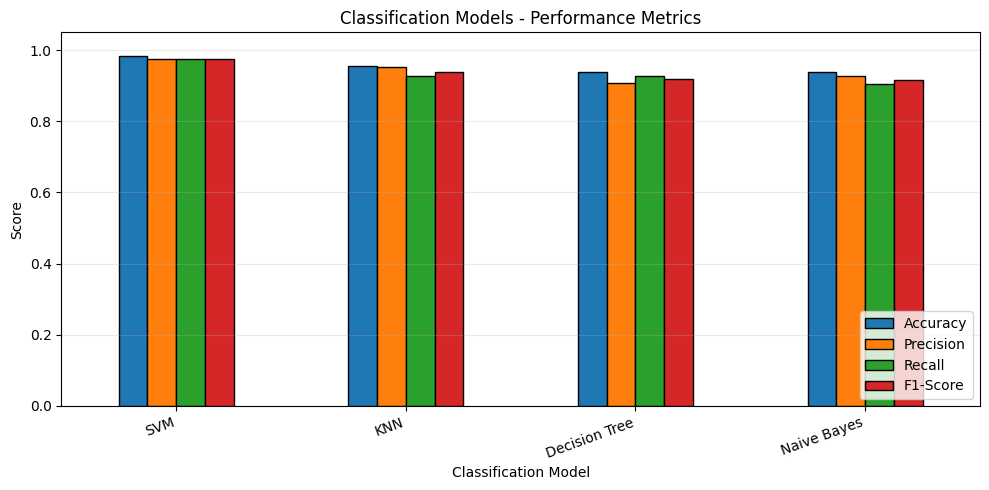

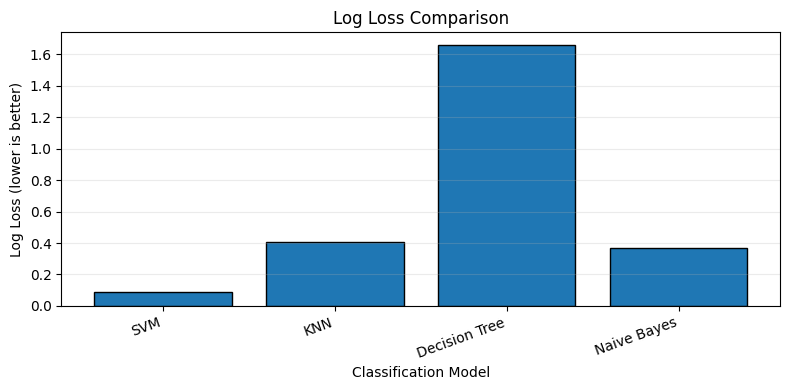

In [ ]:
metric_columns = ["Accuracy", "Precision", "Recall", "F1-Score"]

results_plot = results_df.set_index("Model")

results_plot[metric_columns].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1.05), edgecolor="black"
)
plt.title("Classification Models - Performance Metrics")
plt.xlabel("Classification Model")
plt.ylabel("Score")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.bar(results_df["Model"], results_df["Log Loss"], edgecolor="black")
plt.title("Log Loss Comparison")
plt.xlabel("Classification Model")
plt.ylabel("Log Loss (lower is better)")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# **8. Confusion Matrix Analysis**

A confusion matrix shows correct and incorrect predictions for each class.

- True Negative (TN): Benign observations correctly classified as benign.
- False Positive (FP): Benign observations incorrectly classified as malignant.
- False Negative (FN): Malignant observations incorrectly classified as benign.
- True Positive (TP): Malignant observations correctly classified as malignant.

In this dataset, label 0 is malignant and label 1 is benign. The confusion matrix uses the standard class order [0, 1].

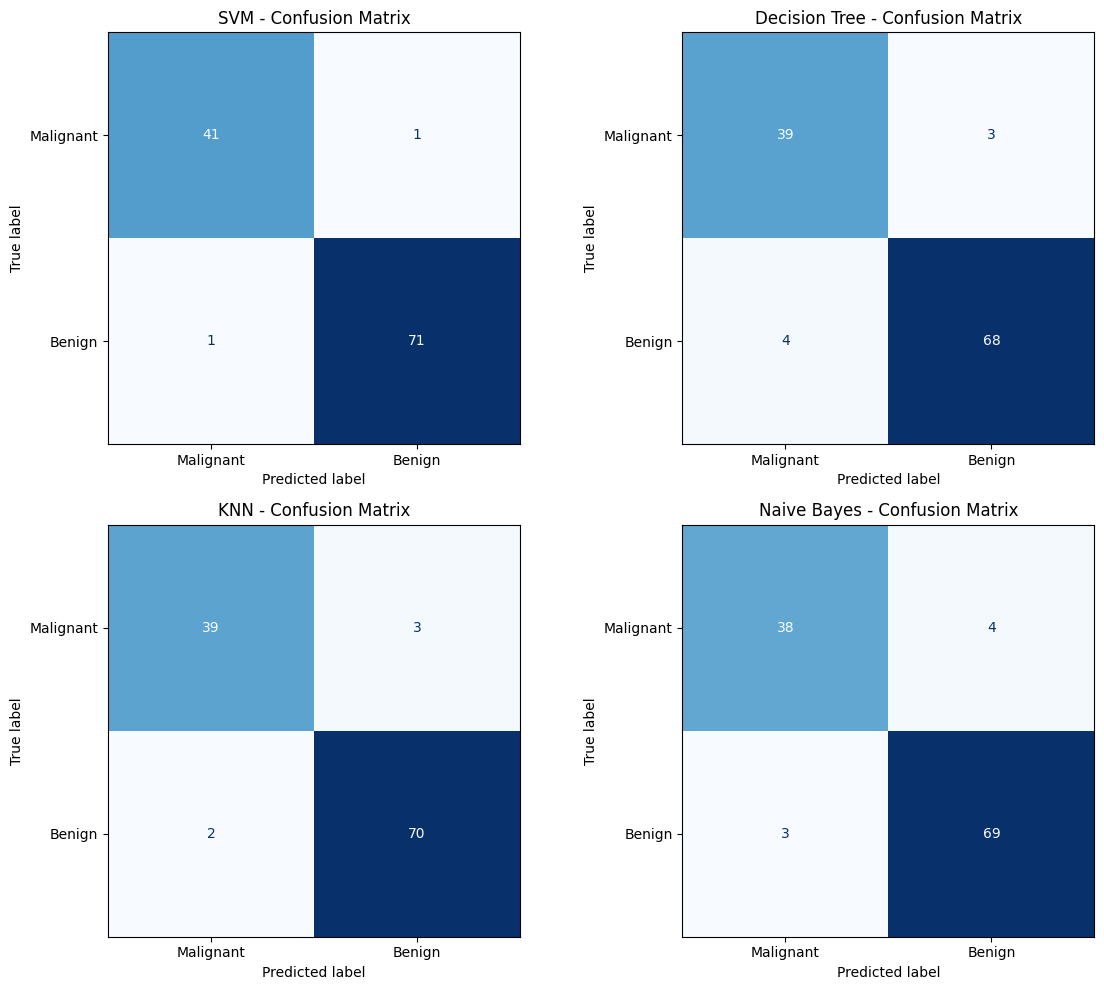

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Malignant", "Benign"]
    )
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name} - Confusion Matrix")

plt.tight_layout()
plt.show()

# **9. Classification Reports**

Display precision, recall, F1-score, and support for both classes. This provides more detail than accuracy alone and helps identify whether a model performs differently for malignant and benign observations.

In [ ]:
for name, y_pred in predictions.items():
    print("=" * 65)
    print(f"Classification Report: {name}")
    print("=" * 65)
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Malignant", "Benign"],
        zero_division=0
    ))

Classification Report: SVM
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Classification Report: Decision Tree
              precision    recall  f1-score   support

   Malignant       0.91      0.93      0.92        42
      Benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114

Classification Report: KNN
              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95    

# **10. Analyze Predicted Probabilities and Log Loss**

Log loss evaluates the probability assigned to the true class. A confident incorrect prediction receives a larger penalty than a less confident incorrect prediction.

The table below compares log loss for all four models. A lower value indicates better probabilistic predictions on this test set. Log loss should be interpreted together with classification metrics because a model can have good class predictions but weaker probability estimates.

In [ ]:
log_loss_df = results_df[["Model", "Log Loss"]].sort_values(
    by="Log Loss"
).reset_index(drop=True)

display(log_loss_df.round(4))

best_log_loss_model = log_loss_df.iloc[0]["Model"]
print("Lowest log loss model:", best_log_loss_model)
print("Log loss:", round(log_loss_df.iloc[0]["Log Loss"], 4))

,Model,Log Loss
0,SVM,0.0860
1,Naive Bayes,0.3713
2,KNN,0.4073
3,Decision Tree,1.6559


Lowest log loss model: SVM
Log loss: 0.086


# **11. Comparative Analysis of Algorithms**

Use the measured test results to compare the algorithms. The observations below describe general algorithm characteristics; the actual ranking must be taken from the executed result table.

| Algorithm | Strengths | Limitations | Suitable applications |
|---|---|---|---|
| SVM | Can learn complex decision boundaries and works well with scaled, high-dimensional features. | Parameter and kernel selection can be difficult; probability estimation adds computational cost. | Text classification, image classification, and medium-sized datasets. |
| Decision Tree | Easy to interpret and can model non-linear relationships. | Can overfit and may be unstable when the data changes. | Rule-based decisions, interpretable classification, and mixed feature relationships. |
| KNN | Simple and makes few assumptions about the decision boundary. | Sensitive to scaling, distance choice, and irrelevant features; prediction can be slow. | Smaller datasets and problems where similar observations tend to share a class. |
| Naïve Bayes | Fast to train and predict; provides probabilities and works well in high-dimensional settings. | Its conditional independence assumption may be unrealistic. | Spam filtering, text classification, and fast baseline models. |

### Interpretation of the experiment

- Compare malignant-class recall to understand how many malignant cases each classifier identifies.
- Compare precision to understand how often a malignant prediction is correct.
- Compare F1-score to balance precision and recall.
- Compare log loss to evaluate the quality of predicted probabilities.
- Consider the confusion matrices to understand the types of classification errors.
- Select a model based on the real application requirements rather than accuracy alone.

# **12. Identify the Best Performing Models**

Generate a concise summary of the model with the highest accuracy, highest malignant-class recall, highest F1-score, and lowest log loss. Different metrics may select different models.

In [ ]:
metric_winners = {
    "Highest Accuracy": results_df.loc[results_df["Accuracy"].idxmax(), "Model"],
    "Highest Malignant Precision": results_df.loc[results_df["Precision"].idxmax(), "Model"],
    "Highest Malignant Recall": results_df.loc[results_df["Recall"].idxmax(), "Model"],
    "Highest F1-Score": results_df.loc[results_df["F1-Score"].idxmax(), "Model"],
    "Lowest Log Loss": results_df.loc[results_df["Log Loss"].idxmin(), "Model"]
}

for metric, model_name in metric_winners.items():
    print(f"{metric}: {model_name}")

print("\nFull comparison:")
display(results_df.round(4))

Highest Accuracy: SVM
Highest Malignant Precision: SVM
Highest Malignant Recall: SVM
Highest F1-Score: SVM
Lowest Log Loss: SVM

Full comparison:


,Model,Accuracy,Precision,Recall,F1-Score,Log Loss
0,SVM,0.9825,0.9762,0.9762,0.9762,0.0860
1,KNN,0.9561,0.9512,0.9286,0.9398,0.4073
2,Decision Tree,0.9386,0.9070,0.9286,0.9176,1.6559
3,Naive Bayes,0.9386,0.9268,0.9048,0.9157,0.3713


# **13. Result and Analysis**

After executing the notebook, use the generated result table, confusion matrices, and classification reports to write the final observations.

- The four required classification algorithms were trained and evaluated on the same held-out test set.
- Accuracy measured overall correctness, while precision and recall focused on the malignant class.
- F1-score provided a balance between malignant-class precision and recall.
- Log loss evaluated the quality of the predicted class probabilities.
- The confusion matrices showed the number and type of classification errors for each algorithm.
- The best algorithm can differ depending on the metric and the requirements of the application.
- In a medical screening context, missing a malignant case can be especially serious, so recall, false negatives, probability calibration, and expert review deserve careful attention.

**Important:** Do not write assumed or fabricated metric values. Use the values produced by your executed notebook and explain which model performs best for each metric.

# **14. Ethical Considerations and Limitations**

- This dataset is provided for educational and research use and does not represent every patient population.
- The classifiers must not be used to diagnose patients or replace qualified medical professionals.
- Dataset bias can lead to unequal performance across different groups.
- False negative predictions may be harmful in a medical screening context.
- False positive predictions can cause unnecessary concern and additional testing.
- Medical data must be handled with privacy, security, and consent safeguards.
- A real-world system would require external validation, fairness analysis, probability calibration, clinical expert review, and appropriate regulatory approval.
- Model performance on one test split does not guarantee performance on new or unseen populations.

# **Conclusion**

In this practical, four classification algorithms—Support Vector Machine, Decision Tree, K-Nearest Neighbors, and Gaussian Naïve Bayes—were implemented using the Wisconsin Diagnostic Breast Cancer dataset.

The models were evaluated using accuracy, precision, recall, F1-score, and log loss. Confusion matrices and classification reports were also used to understand the types of prediction errors made by each classifier.

The comparative analysis demonstrated that different algorithms have different strengths and limitations. The most suitable model depends on the problem, the cost of false predictions, interpretability requirements, and the quality of probability estimates.

Thus, the practical provided an understanding of classification model development, performance evaluation, and comparative analysis.